# **Notebook 1: Data Understanding & Exploratory Data Analysis**
## Assignment: Hybrid RAG & Fine-Tuning for Customer Support
---

### TO-DO: Before Running This Notebook

**Files you NEED for this notebook:**
- [ ] `corporate_policies/` folder with `.md` SOP files uploaded to Colab:
  - `refund_policy.md`, `shipping_delays.md`, `password_reset.md`, `technical_troubleshooting.md`, `escalation_matrix.md`
- [ ] Internet access (to download Bitext dataset from HuggingFace)

**Files this notebook will CREATE:**
- [ ] `sampled_data.csv` — Cleaned, deduplicated, 4000-row sample of the Bitext dataset
  _(Required by: Notebook 2 — Data Preparation)_

> **Note:** Tasks 1.1 (Define Project Scope) and 1.4 (Design Methodology) are documented in your **Project Proposal PDF**, not this notebook. This notebook covers Tasks **1.2** and **1.3**.

---

## **Stage 1: Data Understanding & EDA**
### **Task 1.2: Understand and Assess Data**

#### **1.2.1 Inspect Dataset Structure [2 marks]**
**The Task:** Identify the presence of the corporate policy files within the local environment and successfully download the `bitext` customer support dataset from Hugging Face. Print the dataset information.

**Hints & Tips:**
* Use `glob` to find `.md` files in your workspace, and `load_dataset` for the bitext data.
* The dataset ID is `bitext/Bitext-customer-support-llm-chatbot-training-dataset` — it contains ~26,872 rows.
* Key columns: `instruction` (user query), `intent` (target class), `category` (broader group).

**Why we are doing it:** To ensure the local environment is properly configured with our knowledge base before reading data.
**How we are doing it:** Check the `corporate_policies` directory, load the dataset, and use `.info()`.

**Learner Inference:** If the files load correctly, your environment is stable. Seeing the 'intent' column confirms the target variable you will train your model to extract in Stage 4.

In [ ]:
# YOUR CODE HERE
import glob
import os
from datasets import load_dataset

# ------------------------------------------------------------
# 1. Check for corporate policy Markdown files
# ------------------------------------------------------------
POLICY_DIR = "corporate_policies"

policy_files = glob.glob(os.path.join(POLICY_DIR, "*.md"))

print(f"Found {len(policy_files)} policy file(s) in '{POLICY_DIR}':")
for f in sorted(policy_files):
    print(f"  - {os.path.basename(f)}")

if policy_files:
    print(f"\n✅ Knowledge base loaded — {len(policy_files)} policy documents ready for chunking/retrieval.")
else:
    print(f"\n⚠️ No .md files found in '{POLICY_DIR}'. Check the path and try again.")

# ------------------------------------------------------------
# 2. Load the Bitext customer support dataset from Hugging Face
# ------------------------------------------------------------
DATASET_ID = "bitext/Bitext-customer-support-llm-chatbot-training-dataset"

print(f"\nLoading dataset: {DATASET_ID} ...")
raw_dataset = load_dataset(DATASET_ID)

print("\n✅ Dataset loaded successfully.\n")

# ------------------------------------------------------------
# 3. Print dataset information
# ------------------------------------------------------------
print(raw_dataset)

print("\n--- Column names ---")
print(raw_dataset["train"].column_names)

print(f"\nTotal rows: {len(raw_dataset['train']):,}")

print("\n--- Sample record ---")
sample = raw_dataset["train"][0]
for k, v in sample.items():
    print(f"{k}: {v}")

print("\n--- Key columns preview (instruction / intent / category) ---")
import pandas as pd
df_preview = raw_dataset["train"].select(range(5)).to_pandas()[["instruction", "intent", "category"]]
print(df_preview.to_string(index=False))

Found 13 policy file(s) in 'corporate_policies':
  - account_recovery.md
  - billing_disputes.md
  - data_privacy.md
  - escalation_matrix.md
  - order_tracking.md
  - password_reset.md
  - payment_methods.md
  - product_return.md
  - refund_policy.md
  - shipping_delays.md
  - subscription_cancellation.md
  - technical_troubleshooting.md
  - working_hours.md

✅ Knowledge base loaded — 13 policy documents ready for chunking/retrieval.

Loading dataset: bitext/Bitext-customer-support-llm-chatbot-training-dataset ...


README.md:   0%|          | 0.00/11.9k [00:00<?, ?B/s]

Bitext_Sample_Customer_Support_Training_(…): reconstructing file:   0%|          |  0.00B / 19.2MB            

Bitext_Sample_Customer_Support_Training_(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/26872 [00:00<?, ? examples/s]


✅ Dataset loaded successfully.

DatasetDict({
    train: Dataset({
        features: ['flags', 'instruction', 'category', 'intent', 'response'],
        num_rows: 26872
    })
})

--- Column names ---
['flags', 'instruction', 'category', 'intent', 'response']

Total rows: 26,872

--- Sample record ---
flags: B
instruction: question about cancelling order {{Order Number}}
category: ORDER
intent: cancel_order
response: I've understood you have a question regarding canceling order {{Order Number}}, and I'm here to provide you with the information you need. Please go ahead and ask your question, and I'll do my best to assist you.

--- Key columns preview (instruction / intent / category) ---
                                                 instruction       intent category
            question about cancelling order {{Order Number}} cancel_order    ORDER
  i have a question about cancelling oorder {{Order Number}} cancel_order    ORDER
             i need help cancelling puchase {{Order N

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

#### **1.2.2 Quantify Dataset Characteristics [3 marks]**
**The Task:** Calculate the original size of the dataset, identify the number of unique intents, and randomly sample the dataset down to 4,000 rows.

**Hints & Tips:**
* Use `len()`, `.nunique()`, and `.sample(4000, random_state=42)`.
* `random_state=42` ensures reproducibility — everyone gets the same sample.
* With 4000 rows and 27 intents, you'll get ~148 examples per intent on average.

**Parameter Tuning:**
* `sample(n)` — try 1000–5000 per the workflow spec:
  - `1000`: Fast (~1 min), lower accuracy
  - `4000`: Moderate (~3 min), better accuracy (recommended)
  - `5000`: Slower, best accuracy, may hit T4 memory limits

**Learner Inference:** Capping at 4000 rows keeps your Stage 4 training loop to minutes while providing enough examples per intent.

In [ ]:
# YOUR CODE HERE
# ============================================================
# Dataset sizing: original size, unique intents, random sample to 4,000
# ============================================================

# 1. Original dataset size
from datasets import load_dataset
import pandas as pd

DATASET_ID = "bitext/Bitext-customer-support-llm-chatbot-training-dataset"
raw_dataset = load_dataset(DATASET_ID)
df = raw_dataset["train"].to_pandas()

print(f"Reloaded dataset: {len(df):,} rows")
original_size = len(df)
print(f"Original dataset size: {original_size:,} rows")

# 2. Number of unique intents
num_unique_intents = df["intent"].nunique()
print(f"Number of unique intents: {num_unique_intents}")
print(f"Average examples per intent (at full size): {original_size / num_unique_intents:.1f}")

# 3. Random sample down to 4,000 rows (reproducible)
SAMPLE_SIZE = 4000
df_sampled = df.sample(SAMPLE_SIZE, random_state=42).reset_index(drop=True)

print(f"\nSampled dataset size: {len(df_sampled):,} rows")
print(f"Average examples per intent (post-sample): {len(df_sampled) / num_unique_intents:.1f}")

# ------------------------------------------------------------
# Sanity check: did the sample lose any intent classes entirely?
# ------------------------------------------------------------
intents_in_sample = df_sampled["intent"].nunique()
print(f"\nUnique intents retained in sample: {intents_in_sample} / {num_unique_intents}")

if intents_in_sample < num_unique_intents:
    missing_intents = set(df["intent"].unique()) - set(df_sampled["intent"].unique())
    print(f"⚠️ Intents dropped entirely by random sampling: {missing_intents}")
else:
    print("✅ All intent classes retained in the sample.")

# ------------------------------------------------------------
# Post-sample class balance check
# ------------------------------------------------------------
print("\n--- Post-sample intent distribution (min/max) ---")
sample_intent_counts = df_sampled["intent"].value_counts()
print(f"Max: {sample_intent_counts.max()} ({sample_intent_counts.idxmax()})")
print(f"Min: {sample_intent_counts.min()} ({sample_intent_counts.idxmin()})")
print(f"Imbalance ratio: {sample_intent_counts.max() / sample_intent_counts.min():.1f}x")

Reloaded dataset: 26,872 rows
Original dataset size: 26,872 rows
Number of unique intents: 27
Average examples per intent (at full size): 995.3

Sampled dataset size: 4,000 rows
Average examples per intent (post-sample): 148.1

Unique intents retained in sample: 27 / 27
✅ All intent classes retained in the sample.

--- Post-sample intent distribution (min/max) ---
Max: 169 (delivery_options)
Min: 115 (newsletter_subscription)
Imbalance ratio: 1.5x


#### **1.2.3 Validate Sample Quality [2 marks]**
**The Task:** Identify and remove records containing null values or duplicated customer instructions using normalised deduplication.

**Hints & Tips:**
* Use `.isnull().sum()` to check nulls.
* Simple `drop_duplicates` misses near-dupes like `"Where is my order?"` vs `"where is my order?"`.
* Normalise to lowercase + strip whitespace BEFORE deduplicating to catch these.
* The Bitext dataset typically has ~15 near-duplicates in a 4000-row sample.

**Learner Inference:** Cleaning now prevents "garbage-in, garbage-out". Duplicate prompts can cause leakage between train and test sets later.

In [ ]:
# YOUR CODE HERE
print("--- Null value counts ---")
print(df_sampled.isnull().sum())

total_nulls = df_sampled.isnull().sum().sum()
print(f"\nTotal null values across all columns: {total_nulls}")

if total_nulls > 0:
    rows_with_nulls = df_sampled[df_sampled.isnull().any(axis=1)]
    print(f"Rows containing at least one null: {len(rows_with_nulls)}")
    df_sampled = df_sampled.dropna().reset_index(drop=True)
    print(f"✅ Dropped null rows. New size: {len(df_sampled):,}")
else:
    print("✅ No null values found.")

# ------------------------------------------------------------
# 2. Normalised deduplication on 'instruction'
#    (lowercase + strip BEFORE drop_duplicates — catches
#    "Where is my order?" vs "where is my order?")
# ------------------------------------------------------------
size_before_dedup = len(df_sampled)

df_sampled["instruction_norm"] = df_sampled["instruction"].str.lower().str.strip()

# How many normalised duplicates exist (informational, before dropping)
norm_dupe_count = df_sampled.duplicated(subset=["instruction_norm"]).sum()
print(f"\nNormalised duplicate instructions found: {norm_dupe_count}")

# Show a few examples of what's being caught, for the write-up
dupe_mask = df_sampled.duplicated(subset=["instruction_norm"], keep=False)
if dupe_mask.sum() > 0:
    print("\n--- Sample of duplicate groups (first 3 groups) ---")
    dupe_groups = df_sampled[dupe_mask].sort_values("instruction_norm")
    shown_groups = 0
    for norm_val, group in dupe_groups.groupby("instruction_norm"):
        if shown_groups >= 3:
            break
        print(f"\nGroup: '{norm_val}'")
        print(group[["instruction", "intent"]].to_string(index=False))
        shown_groups += 1

# Drop duplicates, keeping the first occurrence
df_sampled = df_sampled.drop_duplicates(subset=["instruction_norm"], keep="first").reset_index(drop=True)

# Drop the helper column now that dedup is done
df_sampled = df_sampled.drop(columns=["instruction_norm"])

size_after_dedup = len(df_sampled)

print(f"\n--- Deduplication summary ---")
print(f"Size before dedup: {size_before_dedup:,}")
print(f"Size after dedup:  {size_after_dedup:,}")
print(f"Rows removed:      {size_before_dedup - size_after_dedup}")

# ------------------------------------------------------------
# 3. Confirm intent classes survived cleaning
# ------------------------------------------------------------
intents_after = df_sampled["intent"].nunique()
print(f"\nUnique intents retained after cleaning: {intents_after} / {num_unique_intents}")
if intents_after < num_unique_intents:
    print(f"⚠️ Intents lost during cleaning: {set(df['intent'].unique()) - set(df_sampled['intent'].unique())}")
else:
    print("✅ All intent classes still present.")

print(f"\nFinal cleaned dataset size: {len(df_sampled):,} rows")

--- Null value counts ---
flags          0
instruction    0
category       0
intent         0
response       0
dtype: int64

Total null values across all columns: 0
✅ No null values found.

Normalised duplicate instructions found: 98

--- Sample of duplicate groups (first 3 groups) ---

Group: 'another {{account type}} account for father'
                                instruction         intent
another {{Account Type}} account for father create_account
another {{Account Type}} account for father create_account

Group: 'can i order from {{delivery city}}?'
                        instruction           intent
can I order from {{Delivery City}}? delivery_options
can I order from {{Delivery City}}? delivery_options

Group: 'can i order from {{delivery country}}?'
                           instruction           intent
can I order from {{Delivery Country}}? delivery_options
can I order from {{Delivery Country}}? delivery_options

--- Deduplication summary ---
Size before dedup: 4,000
Size

### **Task 1.3: Perform Exploratory Data Analysis**

#### **1.3.1 Perform Univariate Analysis [2 marks]**
**The Task:** Plot the top 10 most frequent customer intents using a horizontal bar chart.

**Hints & Tips:**
* Use a Seaborn `countplot` with `order=df['intent'].value_counts().index[:10]`.
* Check if any single intent dominates >80% of data — signals severe class imbalance.
* `palette="viridis"` works well for accessibility.

**Learner Inference:** This visual reveals class imbalance. If one intent dominates, your fine-tuned router becomes biased toward guessing it.

/tmp/ipykernel_885/776521271.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


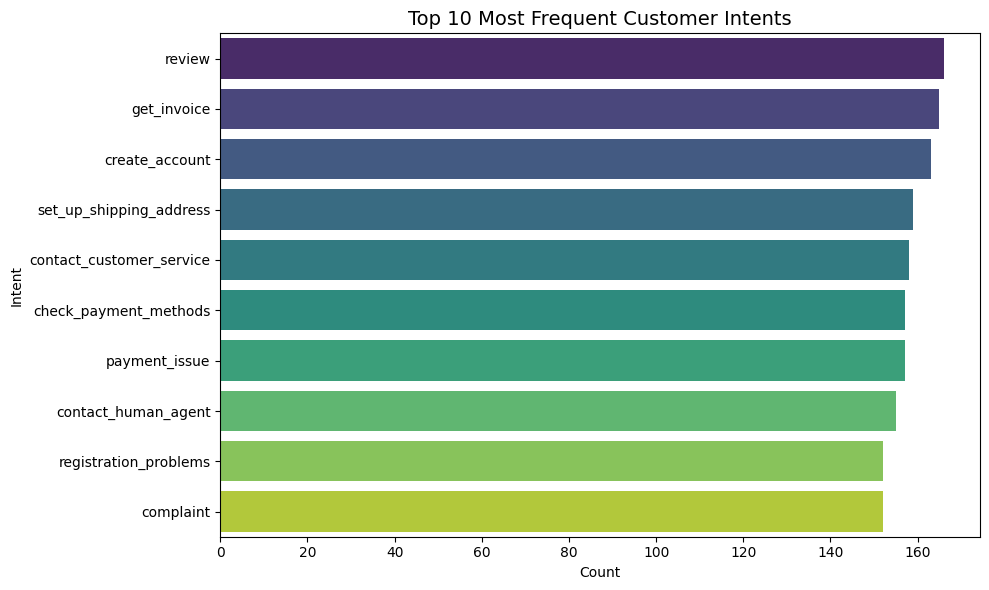

--- Top 10 intents with counts and % share ---
                          count  pct_of_total
intent                                       
review                      166          4.25
get_invoice                 165          4.23
create_account              163          4.18
set_up_shipping_address     159          4.07
contact_customer_service    158          4.05
check_payment_methods       157          4.02
payment_issue               157          4.02
contact_human_agent         155          3.97
registration_problems       152          3.90
complaint                   152          3.90

Most frequent intent: 'review' — 4.2% of dataset
✅ No single intent dominates the dataset (top class < 50%).

Top 10 intents combined share: 40.6% of dataset
Remaining 17 intents share: 59.4%


In [ ]:
# YOUR CODE HERE
import matplotlib.pyplot as plt
import seaborn as sns

top10_order = df_sampled["intent"].value_counts().index[:10]

plt.figure(figsize=(10, 6))
sns.countplot(
    data=df_sampled,
    y="intent",
    order=top10_order,
    palette="viridis"
)
plt.title("Top 10 Most Frequent Customer Intents", fontsize=14)
plt.xlabel("Count")
plt.ylabel("Intent")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Class dominance check — flag if any single intent > 80% of data
# ------------------------------------------------------------
intent_counts = df_sampled["intent"].value_counts()
intent_pct = (intent_counts / len(df_sampled) * 100).round(2)

print("--- Top 10 intents with counts and % share ---")
print(pd.DataFrame({"count": intent_counts.head(10), "pct_of_total": intent_pct.head(10)}))

top_intent_pct = intent_pct.iloc[0]
print(f"\nMost frequent intent: '{intent_counts.index[0]}' — {top_intent_pct:.1f}% of dataset")

if top_intent_pct > 80:
    print("⚠️ Severe class imbalance detected — top intent exceeds 80% of the dataset.")
elif top_intent_pct > 50:
    print("⚠️ Moderate imbalance — top intent exceeds 50% of the dataset.")
else:
    print("✅ No single intent dominates the dataset (top class < 50%).")

# For context: the full spread, not just top 10
print(f"\nTop 10 intents combined share: {intent_pct.head(10).sum():.1f}% of dataset")
print(f"Remaining {len(intent_counts) - 10} intents share: {100 - intent_pct.head(10).sum():.1f}%")

#### **1.3.2 Perform Bivariate Analysis [2 marks]**
**The Task:** Read the text from the uploaded Markdown SOP files and fit a `TfidfVectorizer` (with `stop_words='english'`) to transform them into vectors.

**Hints & Tips:**
* Read files into a list of strings first using `open(f, 'r').read()`.
* `TfidfVectorizer(stop_words="english")` removes common words, keeping meaningful terms.
* The resulting matrix shape should be `(num_docs, num_unique_terms)`.

**Learner Inference:** This transforms raw text into math, letting you prove whether your policies are distinct enough for an AI to tell apart.

In [ ]:
# YOUR CODE HERE
from sklearn.feature_extraction.text import TfidfVectorizer
policy_files = sorted(glob.glob(os.path.join(POLICY_DIR, "*.md")))
policy_names = [os.path.basename(f) for f in policy_files]

policy_texts = []
for fpath in policy_files:
    with open(fpath, "r", encoding="utf-8") as f:
        policy_texts.append(f.read())

print(f"Loaded {len(policy_texts)} policy documents:")
for name, text in zip(policy_names, policy_texts):
    print(f"  - {name}: {len(text):,} characters")

# ------------------------------------------------------------
# 2. Fit TF-IDF vectorizer on the policy texts
# ------------------------------------------------------------
tfidf_vectorizer = TfidfVectorizer(stop_words="english")
tfidf_matrix = tfidf_vectorizer.fit_transform(policy_texts)

print(f"\nTF-IDF matrix shape: {tfidf_matrix.shape}")
print(f"  -> {tfidf_matrix.shape[0]} documents, {tfidf_matrix.shape[1]} unique terms")

feature_names = tfidf_vectorizer.get_feature_names_out()

print("\n--- Top 5 TF-IDF terms per document ---")
for i, name in enumerate(policy_names):
    row = tfidf_matrix[i].toarray().flatten()
    top_indices = row.argsort()[-5:][::-1]
    top_terms = [(feature_names[idx], round(row[idx], 3)) for idx in top_indices]
    print(f"\n{name}:")
    for term, score in top_terms:
        print(f"  {term}: {score}")

# ------------------------------------------------------------
# 3. Quick sanity check — top terms per document
# ------------------------------------------------------------
feature_names = tfidf_vectorizer.get_feature_names_out()

print("\n--- Top 5 TF-IDF terms per document ---")
for i, name in enumerate(policy_names):
    row = tfidf_matrix[i].toarray().flatten()
    top_indices = row.argsort()[-5:][::-1]
    top_terms = [(feature_names[idx], round(row[idx], 3)) for idx in top_indices]
    print(f"\n{name}:")
    for term, score in top_terms:
        print(f"  {term}: {score}")

Loaded 13 policy documents:
  - account_recovery.md: 1,553 characters
  - billing_disputes.md: 1,661 characters
  - data_privacy.md: 1,721 characters
  - escalation_matrix.md: 1,550 characters
  - order_tracking.md: 1,534 characters
  - password_reset.md: 1,604 characters
  - payment_methods.md: 1,629 characters
  - product_return.md: 1,570 characters
  - refund_policy.md: 1,742 characters
  - shipping_delays.md: 1,542 characters
  - subscription_cancellation.md: 1,562 characters
  - technical_troubleshooting.md: 1,646 characters
  - working_hours.md: 1,521 characters

TF-IDF matrix shape: (13, 797)
  -> 13 documents, 797 unique terms

--- Top 5 TF-IDF terms per document ---

account_recovery.md:
  password: 0.255
  attempts: 0.25
  identity: 0.24
  email: 0.209
  account: 0.204

billing_disputes.md:
  charge: 0.416
  authorization: 0.223
  duplicate: 0.223
  refund: 0.198
  billing: 0.162

data_privacy.md:
  data: 0.499
  personal: 0.391
  access: 0.204
  deletion: 0.196
  requests: 0

#### **1.3.3 Generate Visualisations [2 marks]**
**The Task:** Calculate cosine similarity between the TF-IDF vectors of the SOP documents and plot an annotated heatmap.

**Hints & Tips:**
* Use `cosine_similarity` from sklearn and `sns.heatmap` with `annot=True`.
* Diagonal should always be 1.0 (document vs itself).
* Off-diagonal >0.5 = high overlap (RAG may struggle); <0.3 = low overlap (good retrieval).

**Learner Inference:** High overlap (dark off-diagonal squares) means the RAG system struggles to fetch the right doc. Low overlap proves retrieval will be accurate.

Diagonal check (all values = 1.0): ✅ Pass


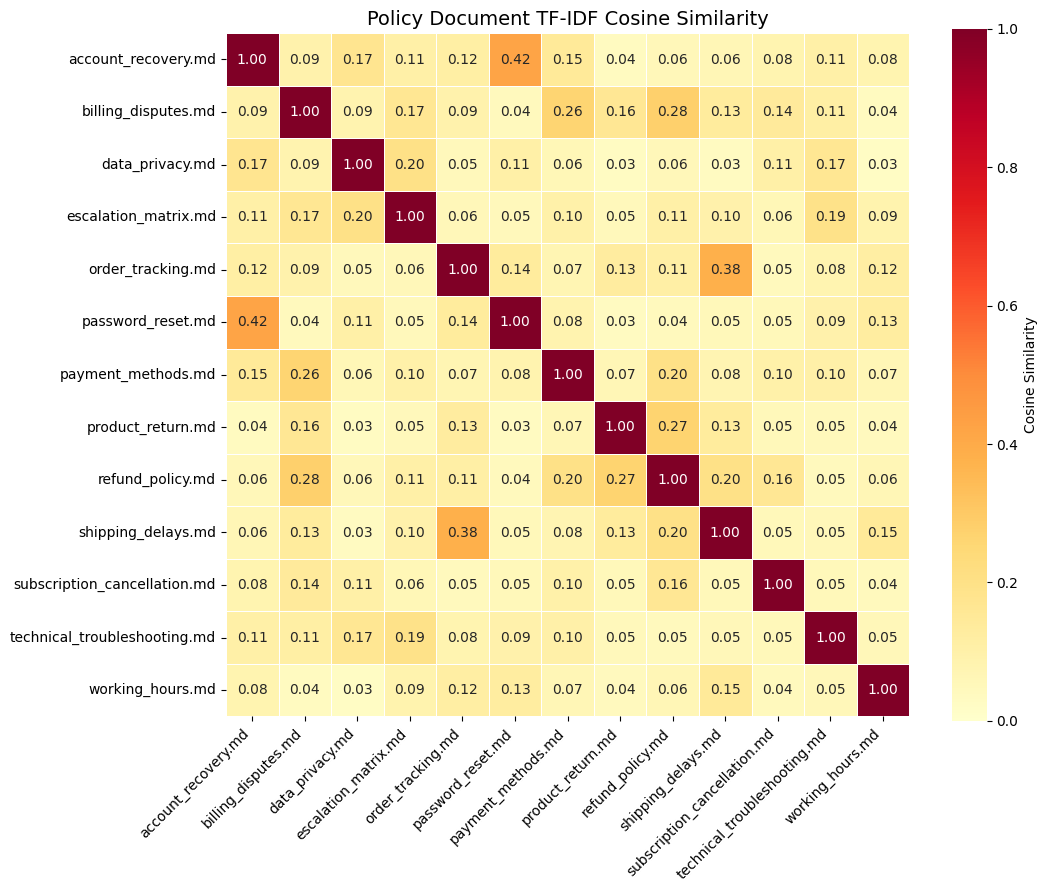


--- Pairwise similarity analysis (excluding self-comparison) ---

⚠️ High overlap pairs (>0.5) — retrieval may confuse these 0 pair(s):

✅ Low overlap pairs (<0.3) — 76 pair(s), good retrieval separation

Average pairwise similarity (off-diagonal): 0.106
Max pairwise similarity: 0.424


In [ ]:
# YOUR CODE HERE
from sklearn.metrics.pairwise import cosine_similarity
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# 1. Compute cosine similarity from the TF-IDF matrix
# ------------------------------------------------------------
cosine_sim_matrix = cosine_similarity(tfidf_matrix)

sim_df = pd.DataFrame(cosine_sim_matrix, index=policy_names, columns=policy_names)

# ------------------------------------------------------------
# 2. Sanity check — diagonal should be 1.0
# ------------------------------------------------------------
diagonal_check = all(abs(cosine_sim_matrix[i, i] - 1.0) < 1e-6 for i in range(len(policy_names)))
print(f"Diagonal check (all values = 1.0): {'✅ Pass' if diagonal_check else '⚠️ Fail'}")

# ------------------------------------------------------------
# 3. Annotated heatmap
# ------------------------------------------------------------
plt.figure(figsize=(11, 9))
sns.heatmap(
    sim_df,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    vmin=0,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Cosine Similarity"}
)
plt.title("Policy Document TF-IDF Cosine Similarity", fontsize=14)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. Flag high-overlap (>0.5) and low-overlap (<0.3) pairs
# ------------------------------------------------------------
print("\n--- Pairwise similarity analysis (excluding self-comparison) ---")

high_overlap_pairs = []
low_overlap_pairs = []

for i in range(len(policy_names)):
    for j in range(i + 1, len(policy_names)):
        score = cosine_sim_matrix[i, j]
        pair = (policy_names[i], policy_names[j], round(score, 3))
        if score > 0.5:
            high_overlap_pairs.append(pair)
        elif score < 0.3:
            low_overlap_pairs.append(pair)

print(f"\n⚠️ High overlap pairs (>0.5) — retrieval may confuse these {len(high_overlap_pairs)} pair(s):")
for a, b, score in sorted(high_overlap_pairs, key=lambda x: -x[2]):
    print(f"  {a} <-> {b}: {score}")

print(f"\n✅ Low overlap pairs (<0.3) — {len(low_overlap_pairs)} pair(s), good retrieval separation")
# (not printing all of these individually — likely most pairs; just the count matters)

# Overall average off-diagonal similarity, as a single summary stat
off_diagonal_vals = [
    cosine_sim_matrix[i, j]
    for i in range(len(policy_names))
    for j in range(len(policy_names))
    if i != j
]
print(f"\nAverage pairwise similarity (off-diagonal): {sum(off_diagonal_vals)/len(off_diagonal_vals):.3f}")
print(f"Max pairwise similarity: {max(off_diagonal_vals):.3f}")

---
## Save Artifacts for Notebook 2

**IMPORTANT:** This cell saves the cleaned DataFrame. Notebook 2 depends on this file.

In [11]:
# YOUR CODE HERE
# ============================================================
# CHECKPOINT: Save cleaned dataset for Notebook 2 (Data_Preparation)
# ============================================================

import os

# ------------------------------------------------------------
# Final sanity check before saving
# ------------------------------------------------------------
print(f"Final row count: {len(df_sampled):,}")
print(f"Columns: {list(df_sampled.columns)}")
print(f"Nulls remaining: {df_sampled.isnull().sum().sum()}")
print(f"Duplicate instructions remaining: "
      f"{df_sampled['instruction'].str.lower().str.strip().duplicated().sum()}")
print(f"Unique intents: {df_sampled['intent'].nunique()}")

assert len(df_sampled) >= 1000, "Dataset below the required minimum of 1,000 records!"
assert len(df_sampled) <= 5000, "Dataset exceeds the required maximum of 5,000 records!"
assert df_sampled.isnull().sum().sum() == 0, "Nulls still present — dedup/cleaning incomplete!"

# ------------------------------------------------------------
# Save to disk (CSV — human-readable, and Parquet — preserves dtypes)
# ------------------------------------------------------------
ARTIFACT_DIR = "artifacts"
os.makedirs(ARTIFACT_DIR, exist_ok=True)

csv_path = os.path.join(ARTIFACT_DIR, "cleaned_dataset.csv")
parquet_path = os.path.join(ARTIFACT_DIR, "cleaned_dataset.parquet")

df_sampled.to_csv(csv_path, index=False)
df_sampled.to_parquet(parquet_path, index=False)

print(f"\n✅ Saved cleaned dataset:")
print(f"  - {csv_path} ({os.path.getsize(csv_path):,} bytes)")
print(f"  - {parquet_path} ({os.path.getsize(parquet_path):,} bytes)")

# ------------------------------------------------------------
# If working in Colab: persist to Google Drive so it survives
# runtime disconnects (uncomment if Drive is mounted)
# ------------------------------------------------------------
from google.colab import drive
drive.mount('/content/drive')
DRIVE_ARTIFACT_DIR = "/content/drive/MyDrive/customer_support_llm_project/artifacts"
os.makedirs(DRIVE_ARTIFACT_DIR, exist_ok=True)
df_sampled.to_csv(os.path.join(DRIVE_ARTIFACT_DIR, "cleaned_dataset.csv"), index=False)
df_sampled.to_parquet(os.path.join(DRIVE_ARTIFACT_DIR, "cleaned_dataset.parquet"), index=False)
print(f"✅ Also persisted to Google Drive: {DRIVE_ARTIFACT_DIR}")

Final row count: 3,902
Columns: ['flags', 'instruction', 'category', 'intent', 'response']
Nulls remaining: 0
Duplicate instructions remaining: 0
Unique intents: 27

✅ Saved cleaned dataset:
  - artifacts/cleaned_dataset.csv (2,777,883 bytes)
  - artifacts/cleaned_dataset.parquet (1,137,978 bytes)
Mounted at /content/drive
✅ Also persisted to Google Drive: /content/drive/MyDrive/customer_support_llm_project/artifacts


---
## END-OF-NOTEBOOK CHECKLIST

> **IMPORTANT: Verify all items before proceeding to Notebook 2.**

- [ ] Bitext dataset loaded and `.info()` printed
- [ ] Dataset sampled to 4000 rows (or chosen size 1000–5000)
- [ ] Nulls inspected, near-duplicates removed via normalised dedup
- [ ] Top 10 intent bar chart rendered
- [ ] TF-IDF vectorisation completed on SOP documents
- [ ] Cosine similarity heatmap rendered
- [ ] **`sampled_data.csv` saved to disk** ← _CRITICAL for Notebook 2_
- [ ] `corporate_policies/` folder still accessible ← _Needed in Notebooks 2 and 4_

**If any item is unchecked, fix it before moving on.**